# Predicting Heart Disease From Clinical Attributes

Problem definition: This definition builds a binary classifier to predict whether a patient has heart disease (target = 1) or not (target = 0) based on 14 attributes 

### Pipeline overview ( Tasks 1-4 )
1. Task 1 - Baseline model: minimal preprocessing (deletion of missing rows)
2. Task 1(continued) - Improved model: full cleaning, imputation, encoding, scaling on the full dataset.
3. Task 2  - 5-Fold Cross- Validation and GridSearchCV, hyperparameter tuning.
4. Task 3  - PCA dimensionality reduction
5. Task 4  - Final comparison of all four models and reflection.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')

## Task 1a : Load and Explore the Dataset

In [2]:
df= pd.read_csv('heart_disease_uci.csv')
print("Shape:", df.shape)
df.head()

Shape: (920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB


 Missing values : Several clinical measurements were not recorded for every patient ( The dataset combines four hospital sites, and thereby not every site ran every test). ca and thal are missing for over half of the patients, and the slope is the third factor missing the most; the rest are missing only a small fraction.


ca          611
thal        486
slope       309
fbs          90
oldpeak      62
trestbps     59
exang        55
thalch       55
chol         30
restecg       2
dtype: int64


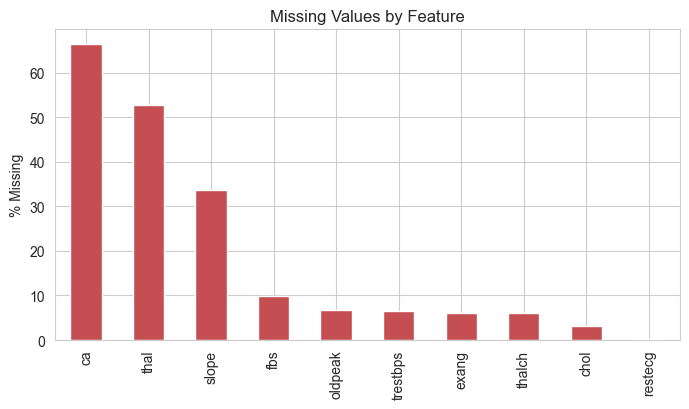

In [4]:
missing = df.isnull().sum()
missing = missing[missing>0].sort_values(ascending=False)
print(missing)

plt.figure(figsize=(7,4.2))
(missing/len(df)*100).plot(kind='bar',color='#C44E52')
plt.ylabel('% Missing')
plt.title('Missing Values by Feature')
plt.tight_layout()
plt.show()

In [5]:
# binary target : 1 = heart disease present, 0= no heart disease
df['target'] = (df['num']>0).astype(int)
print(df['target'].value_counts())
print("\nSex distribution:")
print(df['sex'].value_counts())

target
1    509
0    411
Name: count, dtype: int64

Sex distribution:
sex
Male      726
Female    194
Name: count, dtype: int64


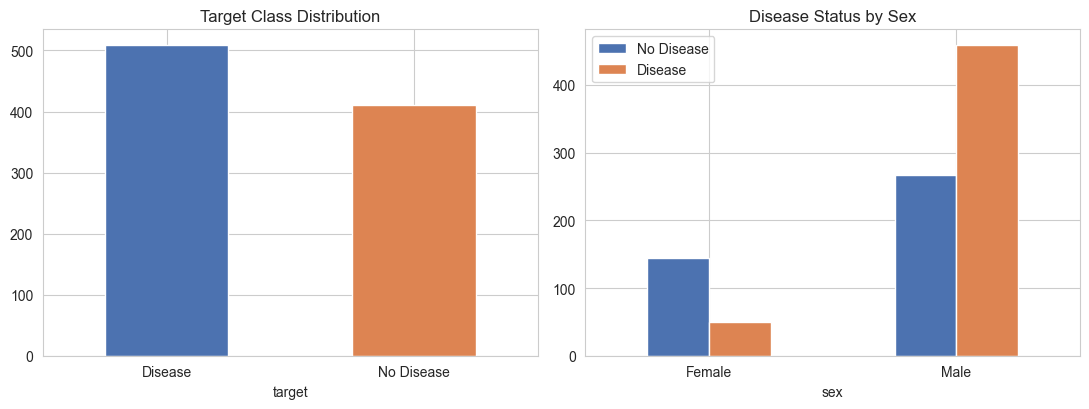

In [6]:
fig, axes= plt.subplots (1, 2, figsize=(11,4.2))
df['target'].map({0:'No Disease', 1:'Disease'}).value_counts().plot(kind='bar', ax=axes[0], color =['#4C72B0','#DD8452']) 
axes[0].set_title('Target Class Distribution') 
axes[0].tick_params(axis='x', rotation=0)

pd.crosstab(df['sex'], df['target']).plot(kind='bar', ax=axes[1], color =['#4C72B0','#DD8452'])
axes[1].set_title('Disease Status by Sex')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(['No Disease','Disease'])
plt.tight_layout()
plt.show()

The dataset is quite balanced between the classes (55% Disease and 45% no disease), but it is imbalanced by sex - about 79% of patients are male and 21% female. This is why the train/test split, when carried out, is stratified on sex as well as target, so both splits preserve the same 79/21 ratio rather than drifting by chance

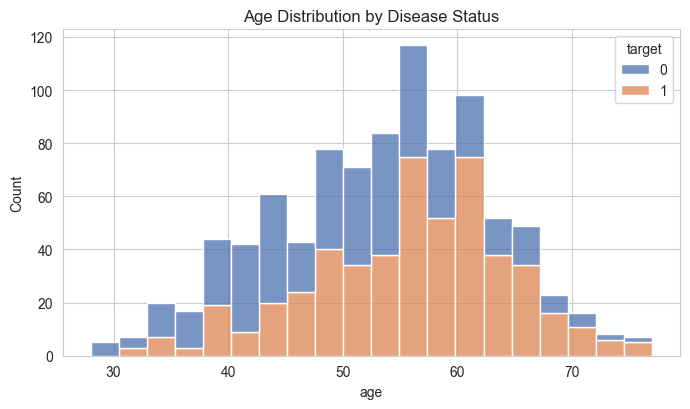

In [7]:
plt.figure(figsize=(7,4.2))
sns.histplot(data=df, x='age', hue='target' , multiple='stack', bins=20, palette=['#4C72B0','#DD8452'])
plt.title('Age Distribution by Disease Status')
plt.tight_layout()
plt.show()

## Task 1b : Baseline Model - Minimal Preprocessing

For the baseline, the simplest approach to preprocessing was taken: drop every row that has any missing value at all, then one-hot encode the categorical features. This method is intentionally basic, enabling us to compare its performance with a more advanced preprocessing strategy developed in Task 1c.

In [8]:
df_baseline = df.dropna().copy()
print("Rows before dropna:", df.shape[0])
print("Rows after dropna:", df_baseline.shape[0], f"({df_baseline.shape[0]/df.shape[0]:.1%} retained)")
print("\nSex distribution after dropna:")
print(df_baseline['sex'].value_counts(normalize=True))

Rows before dropna: 920
Rows after dropna: 299 (32.5% retained)

Sex distribution after dropna:
sex
Male      0.67893
Female    0.32107
Name: proportion, dtype: float64


Dropping missing rows removes 67.5% of the data (920 rows to 299 rows). It changes the male/female balance (79/21 in the full data vs 68/32 after missing values are removed) because the missing values are unevenly distributed across the four hospital sites. Some sites recorded more complete clinical data than others. This shows that deleting incomplete rows doesn't just lose data by chance - it causes bias towards hospitals that recorded more complete information, leaving out others unfairly, which is why imputation, as discussed in Task 1c, is the smarter choice.

In [9]:
cat_cols = ['sex', 'dataset', 'cp', 'restecg', 'exang', 'slope', 'thal', 'fbs']
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca']

def encode(frame, cat_cols):
    """One-hot encode categorical columns; fbs/exang are boolean so map to 0/1 directly."""
    frame = frame.copy()
    bool_like = ['fbs','exang']
    for c in cat_cols:
        if c in bool_like:
            frame[c] = frame[c].fillna(frame[c].mode()[0]).astype(int)
        else:
            frame[c] = frame[c].astype(str)
    to_dummy = [c for c in cat_cols if c not in bool_like]
    frame = pd.get_dummies(frame, columns=to_dummy, drop_first=True)
    return frame

base_enc = encode(df_baseline, cat_cols)
feature_cols_base = [c for c in base_enc.columns if c not in ['id', 'num', 'target']]
X_baseline = base_enc[feature_cols_base]
y_baseline = base_enc['target']
print("Feature matrix shape:", X_baseline.shape)

Feature matrix shape: (299, 20)


In [10]:
# Stratify on target and sex combined, so both classes and both sexes keep the same proportion in train and test.
strat_key_base = df_baseline['target'].astype(str) + '_' + df_baseline['sex'].astype(str)
X_train_baseline, X_test_baseline, y_train_baseline, y_test_baseline = train_test_split( X_baseline, y_baseline, test_size=0.2, random_state=RANDOM_STATE, stratify=strat_key_base)
print("Train shape :", X_train_baseline.shape," Test shape:", X_test_baseline.shape)
print("Female % in train:",(df_baseline.loc[X_train_baseline.index,'sex']=='Female').mean().round(3))
print("Female % in test: ", (df_baseline.loc[X_test_baseline.index,'sex']=='Female').mean().round(3))

Train shape : (239, 20)  Test shape: (60, 20)
Female % in train: 0.322
Female % in test:  0.317


In [11]:
rf_baseline = RandomForestClassifier(random_state=RANDOM_STATE)
rf_baseline.fit(X_train_baseline, y_train_baseline)

pred_baseline = rf_baseline.predict(X_test_baseline)
proba_baseline = rf_baseline.predict_proba(X_test_baseline)[:,1]

print(classification_report(y_test_baseline, pred_baseline, target_names=['No Disease','Disease']))
print("ROC-AUC:", round(roc_auc_score(y_test_baseline, proba_baseline),4))

              precision    recall  f1-score   support

  No Disease       0.84      0.81      0.83        32
     Disease       0.79      0.82      0.81        28

    accuracy                           0.82        60
   macro avg       0.82      0.82      0.82        60
weighted avg       0.82      0.82      0.82        60

ROC-AUC: 0.8795


In [12]:
def metrics_block(y_true,y_pred,y_proba=None):
    cm = confusion_matrix(y_true,y_pred)
    tn,fp,fn,tp = cm.ravel()
    specificity =tn / (tn + fp) if (tn + fp) > 0 else np.nan 
    out = {
        'accuracy'  : accuracy_score(y_true, y_pred),
        'precision' : precision_score(y_true, y_pred, zero_division=0),
        'recall_sensitivity' : recall_score(y_true, y_pred, zero_division=0),
        'specificity' : specificity,
        'f1' : f1_score(y_true, y_pred, zero_division=0),
        'confusion_matrix':cm,
    }
    if y_proba is not None:
        out['roc_auc'] = roc_auc_score(y_true, y_proba)
    return out
results = {}
results['baseline'] = metrics_block(y_test_baseline, pred_baseline, proba_baseline)
results['baseline']

{'accuracy': 0.8166666666666667,
 'precision': 0.7931034482758621,
 'recall_sensitivity': 0.8214285714285714,
 'specificity': np.float64(0.8125),
 'f1': 0.8070175438596491,
 'confusion_matrix': array([[26,  6],
        [ 5, 23]]),
 'roc_auc': 0.8794642857142858}

## Task 1c : Improved Model - Proper Preprocessing

Instead of discarding rows, now missing values are imputed (median for numeric columns, mode for categorical columns), keeping all 920 patients. Scaling is also done for the numeric features with StandardScaler - this doesn't change what a Random Forest does with the raw features, but it is required later for PCA, and it keeps the preprocessing pipeline consistent across every subsequent stage so the comparison in Task 4 is fair.

In [13]:
df_improved = df.copy()
for c in num_cols:
    df_improved[c] = df_improved[c].fillna(df_improved[c].median())
for c in ['fbs', 'restecg', 'exang', 'slope', 'thal']:
    df_improved[c] = df_improved[c].fillna(df_improved[c].mode()[0])
print("Shape after imputation:", df_improved.shape)
print("Remaining missing values:", df_improved[num_cols + ['fbs', 'restecg', 'exang', 'slope', 'thal']].isnull().sum().sum())

Shape after imputation: (920, 17)
Remaining missing values: 0


In [14]:
improved_enc = encode(df_improved, cat_cols)
feature_cols_improved = [c for c in improved_enc.columns if c not in ['id','num','target']]
X_improved = improved_enc[feature_cols_improved]
y_improved = improved_enc['target']

strat_key_improved = df_improved['target'].astype(str) + '_' + df_improved['sex'].astype(str)
X_train_improved, X_test_improved, y_train_improved, y_test_improved = train_test_split(
X_improved, y_improved, test_size=0.2, random_state= RANDOM_STATE, stratify=strat_key_improved)

scaler = StandardScaler()
X_train_improved_scaled = pd.DataFrame(scaler.fit_transform(X_train_improved), columns= X_train_improved.columns, index=X_train_improved.index)
X_test_improved_scaled = pd.DataFrame(scaler.transform(X_test_improved), columns= X_test_improved.columns, index=X_test_improved.index)

print("Train shape:", X_train_improved_scaled.shape," Test shape:", X_test_improved_scaled.shape)
print("Female % in train:", (df_improved.loc[X_train_improved.index,'sex']=='Female').mean().round(3))
print("Female % in test:", (df_improved.loc[X_test_improved.index,'sex']=='Female').mean().round(3))


Train shape: (736, 21)  Test shape: (184, 21)
Female % in train: 0.211
Female % in test: 0.212


In [15]:
rf_improved = RandomForestClassifier (random_state = RANDOM_STATE)
rf_improved.fit(X_train_improved_scaled, y_train_improved)

pred_improved = rf_improved.predict(X_test_improved_scaled)
proba_improved = rf_improved.predict_proba(X_test_improved_scaled)[:,1]

results['improved'] = metrics_block (y_test_improved, pred_improved, proba_improved)
print(classification_report(y_test_improved, pred_improved, target_names=['No Disease','Disease']))
print("ROC-AUC:", round(roc_auc_score(y_test_improved, proba_improved), 4))


              precision    recall  f1-score   support

  No Disease       0.88      0.78      0.83        82
     Disease       0.84      0.91      0.87       102

    accuracy                           0.85       184
   macro avg       0.86      0.85      0.85       184
weighted avg       0.86      0.85      0.85       184

ROC-AUC: 0.9214


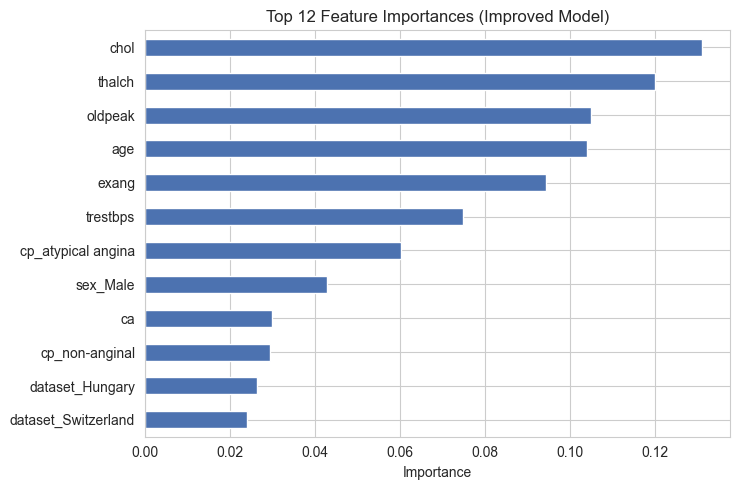

chol                  0.131068
thalch                0.120039
oldpeak               0.104934
age                   0.103954
exang                 0.094280
trestbps              0.074904
cp_atypical angina    0.060196
sex_Male              0.042716
ca                    0.029964
cp_non-anginal        0.029373
dtype: float64

In [16]:
importances = pd.Series(rf_improved.feature_importances_, index=X_train_improved_scaled.columns).sort_values(ascending=False)

plt.figure(figsize=(7.5,5))
importances.head(12).sort_values().plot(kind='barh',color='#4C72B0')
plt.title('Top 12 Feature Importances (Improved Model)')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()
importances.head(10)

Cholesterol, thalch (max heart rate achieved), oldpeak (ST depression), and age are the strongest predictors. This provides confidence that the model has captured clinical patterns rather than simply fitting noise.

## Task 2 : Cross-Validation and Hyperparameter Tuning

Cross-validation: A single train/test split provides one accuracy result that depends on which 20% of patients fall into the test set. With only 184 test patients, the numbers can shift by several percentage points just from sampling luck.
5-fold cross-validation trains and evaluates the model 5 times on different folds of the training data and averages the result, giving a more reliable estimate of how the model will generalise. In addition, the standard deviation across folds shows how stable the estimate is.

Hyperparameter tuning: GridSearchCV is used to search over Random Forest hyperparameters.

Every combination is evaluated with 5-fold CV on the training set only  ( the test set stays untouched until final evaluation), and the combination with the highest mean CV accuracy is selected.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores_default = cross_val_score(RandomForestClassifier(random_state=RANDOM_STATE),
                                    X_train_improved_scaled, y_train_improved,cv=cv, scoring='accuracy')
print("Per-fold accuracy:", np.round(cv_scores_default, 4))
print(f"Mean CV accuracy: {cv_scores_default.mean():.4f} (+/- {cv_scores_default.std():.4f})")


Per-fold accuracy: [0.7568 0.7823 0.8095 0.8163 0.8435]
Mean CV accuracy: 0.8017 (+/- 0.0297)


In [18]:
param_grid = {
    'n_estimators' : [100,200],
    'max_depth' : [None,5,10],
    'min_samples_split' : [2,5],
    'min_samples_leaf' : [1,2],
    'max_features' : ['sqrt', 'log2'],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1,
)
grid.fit(X_train_improved_scaled, y_train_improved)
print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))

    

Best parameters: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
Best CV accuracy: 0.8207


In [19]:
rf_tuned = grid.best_estimator_
pred_tuned = rf_tuned.predict(X_test_improved_scaled)
proba_tuned = rf_tuned.predict_proba(X_test_improved_scaled)[:,1]

results['tuned'] = metrics_block(y_test_improved, pred_tuned, proba_tuned)
print(classification_report(y_test_improved, pred_tuned, target_names=['No Disease','Disease']))
print("ROC-AUC:", round(roc_auc_score(y_test_improved, proba_tuned),4))

              precision    recall  f1-score   support

  No Disease       0.91      0.78      0.84        82
     Disease       0.84      0.94      0.89       102

    accuracy                           0.87       184
   macro avg       0.88      0.86      0.87       184
weighted avg       0.87      0.87      0.87       184

ROC-AUC: 0.932


The tuned model's cross-validation accuracy was also calculated on the training data, using the same 5-fold approach as the default model, to allow a fair comparison between the two.

In [20]:
cv_scores_tuned = cross_val_score(rf_tuned, X_train_improved_scaled, y_train_improved, cv=cv, scoring='accuracy')
print("Per-Fold accuracy:", np.round(cv_scores_tuned,4))
print(f"Mean CV accuracy: {cv_scores_tuned.mean():.4f} (+/- {cv_scores_tuned.std():.4f})")

Per-Fold accuracy: [0.7635 0.8095 0.8231 0.8435 0.8639]
Mean CV accuracy: 0.8207 (+/- 0.0340)


## Task 3 : Feature Reduction with PCA


After one-hot encoding, the dataset expanded to 21 input features, including several binary columns derived from the same original categories (such as chest pain type and hospital site), which are inherently related to one another. PCA was applied to the scaled feature set to join this related information to a smaller number of independent components, retaining at least 90% of the total variance.

Components needed for 90% variance: 14 (out of 21 original features)


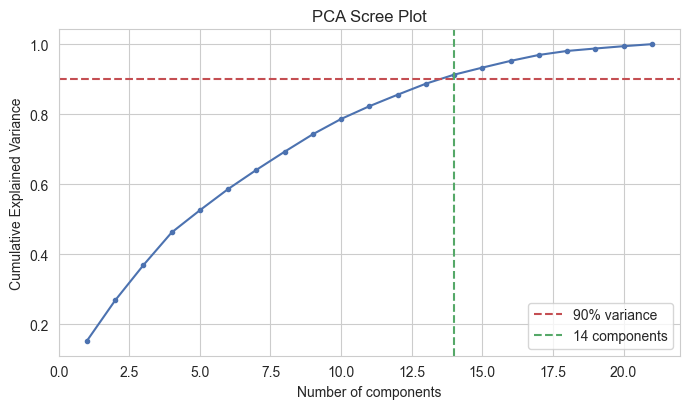

In [21]:
pca_explorer = PCA(random_state=RANDOM_STATE)
pca_explorer.fit(X_train_improved_scaled)

cum_var = np.cumsum(pca_explorer.explained_variance_ratio_)
n_components_90 = int(np.argmax(cum_var >= 0.90)+1)
print(f"Components needed for 90% variance: {n_components_90} (out of {X_train_improved_scaled.shape[1]} original features)")

plt.figure(figsize=(7,4.2))
plt.plot(range(1,len(cum_var)+1),cum_var, marker='o', markersize=3, color='#4C72B0')
plt.axhline(0.90,color='#C44E52', linestyle='--', label='90% variance')
plt.axvline(n_components_90, color='#55A868', linestyle='--', label=f'{n_components_90} components')
plt.xlabel('Number of components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Scree Plot')
plt.legend()
plt.tight_layout()
plt.show()


In [22]:
pca = PCA(n_components=n_components_90, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_improved_scaled)
X_test_pca = pca.transform(X_test_improved_scaled)

print("PCA train shape:", X_train_pca.shape, "PCA test shape:", X_test_pca.shape)

PCA train shape: (736, 14) PCA test shape: (184, 14)


The best hyperparameters found in Task 2 are reused, so that the comparison in Task 4 isolates the effect of feature reduction rather than mixing it with a hyperparameter change.

In [23]:
rf_pca = RandomForestClassifier(random_state=RANDOM_STATE, **grid.best_params_)
rf_pca.fit(X_train_pca, y_train_improved)

pred_pca = rf_pca.predict(X_test_pca)
proba_pca = rf_pca.predict_proba(X_test_pca)[:,1]

results['pca'] = metrics_block(y_test_improved, pred_pca, proba_pca)
print(classification_report(y_test_improved, pred_pca, target_names=['No Disease','Disease']))
print("ROC-AUC:", round(roc_auc_score(y_test_improved, proba_pca),4))

              precision    recall  f1-score   support

  No Disease       0.93      0.80      0.86        82
     Disease       0.86      0.95      0.90       102

    accuracy                           0.89       184
   macro avg       0.89      0.88      0.88       184
weighted avg       0.89      0.89      0.88       184

ROC-AUC: 0.9442


In [24]:
cv_scores_pca = cross_val_score(rf_pca, X_train_pca, y_train_improved, cv=cv, scoring='accuracy')
print("Per-fold accuracy:", np.round(cv_scores_pca,4))
print(f"Mean CV accuracy: {cv_scores_pca.mean():.4f} (+/-{cv_scores_pca.std():.4f})")

Per-fold accuracy: [0.777  0.8027 0.8435 0.8095 0.8299]
Mean CV accuracy: 0.8125 (+/-0.0229)


## Task 4 : Model Comparison and Reflection

The table below compares all four stages on the same test set, using the same metrics: accuracy, precision, recall (sensitivity), specificity, F1-score, and ROC-AUC.

Sensitivity (recall) matters more clinically: it is the proportion of actual disease cases the model correctly flags - missing a sick patient (false negative) is more costly than a false alarm.

Specificity is the proportion of healthy patients correctly identified as healthy - low specificity means healthy patients are unnecessarily flagged for further testing.

In [25]:
comparison = pd.DataFrame({
    'Baseline(raw,dropna)': results['baseline'],
    'Improved (imputed+scaled)': results['improved'],
    'Tuned (GridSearchCV)': results['tuned'],
    'PCA-reduced': results['pca'],
}).T
comparison_display= comparison[['accuracy', 'precision', 'recall_sensitivity', 'specificity', 'f1', 'roc_auc']].astype(float).round(4)
comparison_display

,accuracy,precision,recall_sensitivity,specificity,f1,roc_auc
"Baseline(raw,dropna)",0.8167,0.7931,0.8214,0.8125,0.8070,0.8795
Improved (imputed+scaled),0.8533,0.8378,0.9118,0.7805,0.8732,0.9214
Tuned (GridSearchCV),0.8696,0.8421,0.9412,0.7805,0.8889,0.9320
PCA-reduced,0.8859,0.8584,0.9510,0.8049,0.9023,0.9442


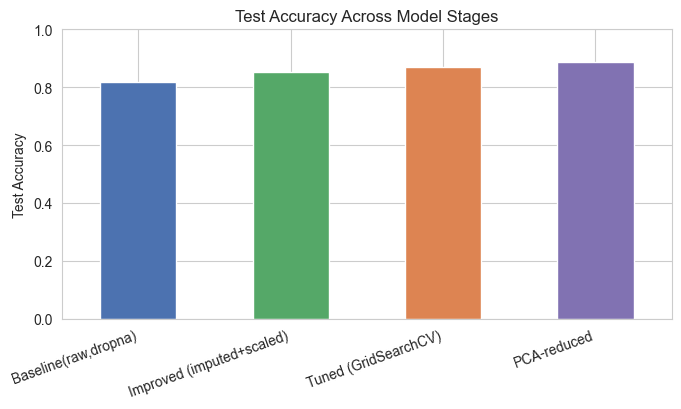

In [26]:
plt.figure(figsize=(7,4.2))
comparison_display['accuracy'].plot(kind='bar',color=['#4C72B0','#55A868','#DD8452','#8172B2'])
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy Across Model Stages')
plt.xticks(rotation=20,ha='right')
plt.ylim(0,1)
plt.tight_layout()
plt.show()

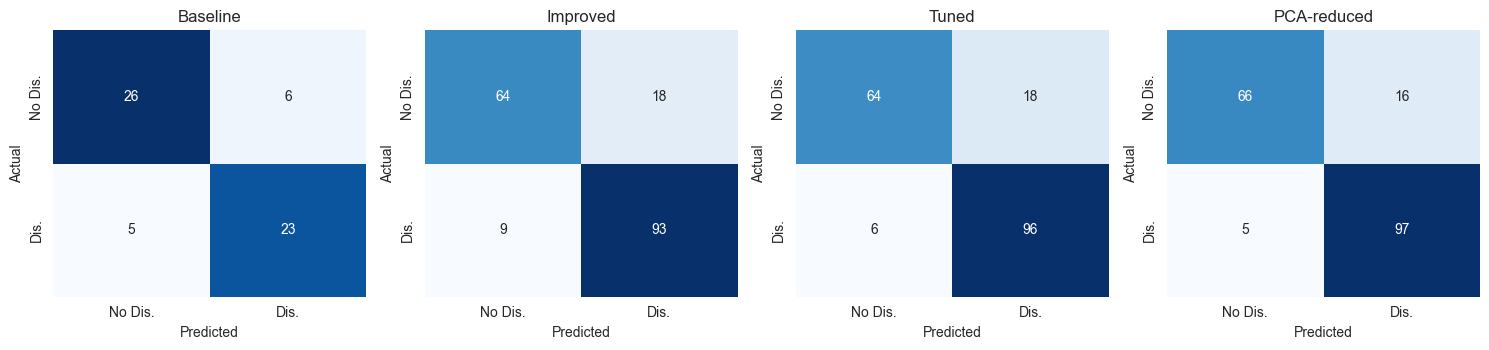

In [27]:
fig, axes = plt.subplots(1,4,figsize=(15,3.6))
stage_names = ['Baseline','Improved','Tuned','PCA-reduced']
cms = [results['baseline']['confusion_matrix'],results['improved'] ['confusion_matrix'],
       results['tuned']['confusion_matrix'], results['pca']['confusion_matrix']]
for ax, name, cm in zip (axes, stage_names, cms):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['No Dis.', 'Dis.'], yticklabels=['No Dis.','Dis.'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

# Reflection

Best- performing model: The PCA- reduced model achieves the highest accuracy (0.886), F1-score (0.902), and ROC-AUC(0.944), closely followed by the tuned model. However, this ranking does not fully hold under cross- validation: the tuned model's mean CV accuracy (0.8207) is slightly higher than the PCA model's (0.8125), suggesting the two are closely matched in reliability, and that the PCA model's test-set advantage may be influenced partly by which specific patients fall into the particular test split.

Evidence of overfitting: The cross-validation mean accuracy on the training folds (0.80 - 0.82) is noticeably lower than the test-set accuracy (0.87-0.89) for the tuned and PCA models. This gap is worth flagging rather than ignoring. It's not a classic sign of overfitting, where it shows strong training performance but weaker test performance. Instead, the cross-validation result is likely the accurate measure, while the single test-set score, based on only 184 patients, is probably slightly optimistically biased due to the natural variation in which patients are included. The cross-validation is therefore a more trustworthy indicator of how well the model would generalise to new patients, and it shows a clear, real improvement from the untuned model (0.80) to the tuned model (0.82)

What was learned at each stage:
1. Feature engineering/ data quality: Dropping incomplete rows discarded 67% of patients and slightly distorted the sex balance of the sample - a hidden cost of simple preprocessing that is only visible once the group ratios are checked. Proper imputation retained the full sample and immediately improved accuracy, precision and recall, confirming that data preparation has a bigger impact than any later modelling choice.

2. Cross Validation - A single test-set score is noisy with a dataset with only 184 patients; 5-fold CV provided a better estimate of reliability for the model and revealed that the test-set score alone was somewhat optimistic.

3. Hyperparameter tuning - Limiting how deep the tree could grow, requiring more patients per split, improved both cross-validation score and the test-set results. This suggests the default setting was letting the model fit too closely to random patterns in training data.

4.  Feature reduction (PCA)- Reducing the 21 encoded features to 14 components (while keeping 90% of the original information) improved the test-set accuracy further (from 0.870 to 0.886). However, its cross-validation score (0.8125) was slightly lower than the tuned model's (0.8207). This means PCA's improvement on the test set should be treated with caution, as it may partly reflect the specific patients in the test split rather than a consistently better model. Overall, the tuned and PCA-reduced models perform similarly, rather than one being clearly better performing than the other.

Another limitation lies with the variable ‘dataset’, which contains the hospital site information (Cleveland, Hungary, Switzerland, VA Long Beach) and is part of the set of predictors in one-hot encoding form. This is a plausible decision since being at a specific hospital site could represent actual differences in patient populations. However, since missingness patterns differ systematically by site, the model may partly learn hospital-specific patterns rather than genuine clinical risk factors. Future work could test this by excluding ‘dataset’ and checking whether performance remains high using only clinical variables.

Name: Methuki Pehansa De Silva

Student ID: G21407229